# Modularity on the Karate Club Graph
**DSC212: Graph Theory — Research Assignment**

**Name:** N Javeed Akbar  **RollNO.:** IMS25134

Recursive spectral modularity partitioning implemented from scratch (NumPy + NetworkX only),
following Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577-8582.

**Notebook map**
1. Setup and the modularity matrix `B` (with numerical checks of Propositions 1 and 2)
2. Core algorithm: leading eigenpair, bisection, recursive bisection
3. Run on the Karate Club graph + split log
4. Visualization after every split
5. Node metrics after every split and their evolution
6. Comparison with the real split (Mr. Hi vs. Officer)
7. Extra samples: more graphs, planted-partition (SBM) experiments, comparison with other methods
8. Discussion

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque
from math import comb

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("networkx", nx.__version__, "| numpy", np.__version__)

networkx 3.7 | numpy 2.4.6


### 1.1 Load the graph and build `B`
$A$ is the adjacency matrix, $k$ the degree vector, $m=|E|$, and
$B = A - \dfrac{k k^\top}{2m}$.  We also store Zachary's *ground truth* (which faction each member joined).

In [2]:
G = nx.karate_club_graph()
for _, _, d in G.edges(data=True):       # recent NetworkX versions ship interaction-count weights;
    d.clear()                            # the handout uses the simple 0/1 graph (78 edges), so drop them
nodes = list(G.nodes())                  # 0..33
n, m = G.number_of_nodes(), G.number_of_edges()
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

truth = np.array([1 if G.nodes[i]["club"] == "Mr. Hi" else -1 for i in nodes])
print(f"n = {n}, m = {m}, sum(k) = {int(k.sum())} (= 2m = {2*m})")
print("Mr. Hi faction:", int((truth == 1).sum()), "members | Officer faction:", int((truth == -1).sum()), "members")

# Proposition 1: B is real symmetric
assert np.allclose(B, B.T)
# Proposition 2: B @ 1 = 0, so 0 is always an eigenvalue of the full B
assert np.allclose(B @ np.ones(n), 0)
# Corollary 1: trivial partition has Q = 0
print("1^T B 1 / 4m =", float(np.ones(n) @ B @ np.ones(n) / (4 * m)))
eigvals = np.linalg.eigvalsh(B)
print("Top 5 eigenvalues of B:", eigvals[::-1][:5])
print("Smallest |eigenvalue| (should be ~0):", float(np.min(np.abs(eigvals))))

n = 34, m = 78, sum(k) = 156 (= 2m = 156)
Mr. Hi faction: 17 members | Officer faction: 17 members
1^T B 1 / 4m = 1.120898246015783e-17
Top 5 eigenvalues of B: [4.977 3.043 2.32  1.489 1.459]
Smallest |eigenvalue| (should be ~0): 9.662245470747e-17


## 2. Core algorithm

**Design notes**

* `modularity_Q` evaluates $Q=\frac{1}{2m}\sum_{C}\big(e_C - \frac{(\sum_{i\in C}k_i)^2}{2m}\big)$ **directly from a partition**
  (any number of communities). This is independent of the eigenvector code, so it is a genuine check.
* `bisect` follows the handout: take the block $B^{(C)}$ of the global $B$, compute its leading eigenpair with `numpy.linalg.eigh`,
  stop if $\lambda_1\le 0$, otherwise split by the sign of $u_1$.
* **Optional refinement (`generalized=True`)**: Newman's paper subtracts the row sums on the diagonal,
  $B^{(C)}_{ij} \leftarrow B^{(C)}_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$, which makes $s^\top B^{(C)}s/4m$ the *exact* modularity change.
  The handout's plain block is the default; the refinement is used later as a comparison.
* `require_gain=True` adds Newman's safeguard: because the sign-rounded vector is only an approximation of the relaxed optimum,
  a split with $\lambda_1>0$ is accepted only if the true modularity $Q$ really goes up. Together with `generalized=True`
  this is Newman's full algorithm.

In [3]:
def modularity_matrix(A):
    k = A.sum(axis=1)
    return A - np.outer(k, k) / k.sum()

def modularity_Q(A, communities):
    # Q computed straight from the definition for an arbitrary partition.
    two_m = A.sum()
    k = A.sum(axis=1)
    Q = 0.0
    for C in communities:
        idx = list(C)
        Q += A[np.ix_(idx, idx)].sum() - k[idx].sum() ** 2 / two_m
    return Q / two_m

def leading_eigpair(M):
    vals, vecs = np.linalg.eigh(M)       # ascending order, symmetric input
    return vals[-1], vecs[:, -1]

def bisect(B, C, generalized=False, tol=1e-10):
    # Try to split community C. Returns (C_plus, C_minus, lam) or (None, None, lam).
    idx = np.array(sorted(int(i) for i in C))
    BC = B[np.ix_(idx, idx)].copy()      # restricted modularity matrix B^(C)
    if generalized:
        BC -= np.diag(BC.sum(axis=1))
    lam, u = leading_eigpair(BC)
    if lam <= tol:                       # Theorem 3: no split can help
        return None, None, lam
    s = np.where(u > 0, 1, -1)           # threshold at zero
    if abs(int(s.sum())) == len(s):      # everyone on one side -> no real split
        return None, None, lam
    return idx[s == 1].tolist(), idx[s == -1].tolist(), lam

def recursive_bisection(A, generalized=False, require_gain=False):
    # Recursive spectral bisection. Returns a history (one snapshot per split) and a log of every test.
    n = A.shape[0]
    B = modularity_matrix(A)
    communities = [list(range(n))]
    color = np.zeros(n, dtype=int)       # stable colour ids across iterations
    next_color = 1
    queue = deque([tuple(range(n))])
    history = [dict(iteration=0, communities=[list(c) for c in communities], color=color.copy(),
                    split=None, lam=None, Q=modularity_Q(A, communities), dQ=0.0)]
    log = []
    it = 0
    while queue:
        C = list(queue.popleft())
        Cp, Cm, lam = bisect(B, C, generalized)
        if Cp is None:
            log.append(dict(community_size=len(C), lam=lam, action="stop (indivisible)"))
            continue
        trial = [c for c in communities if sorted(c) != sorted(C)] + [Cp, Cm]
        Q_prev, Q_new = history[-1]["Q"], modularity_Q(A, trial)
        if require_gain and Q_new <= Q_prev + 1e-12:      # Newman's safeguard: lambda > 0 alone is not sufficient
            log.append(dict(community_size=len(C), lam=lam, action="stop (rounded split has no gain)"))
            continue
        it += 1
        # replace C by its two halves; C+ keeps the parent colour, C- gets a new one
        communities = trial
        color[Cm] = next_color; next_color += 1
        history.append(dict(iteration=it, communities=[list(c) for c in communities], color=color.copy(),
                            split=(len(Cp), len(Cm)), lam=lam, Q=Q_new, dQ=Q_new - Q_prev))
        log.append(dict(community_size=len(C), lam=lam, action=f"split -> {len(Cp)} + {len(Cm)}"))
        queue.extend([tuple(Cp), tuple(Cm)])
    return history, log

## 3. Run on the Karate Club graph

In [4]:
history, log = recursive_bisection(A, generalized=False)

rows = []
for h in history:
    rows.append({"iteration": h["iteration"], "#communities": len(h["communities"]),
                 "split sizes": h["split"], "lambda_1": h["lam"], "Q": h["Q"], "dQ (true)": h["dQ"]})
summary = pd.DataFrame(rows).set_index("iteration")
display(summary)

print("\nEvery eigenvalue test (including the ones that stopped the recursion):")
print(pd.DataFrame(log).to_string(index=False))

final = history[-1]["communities"]
print("\nFinal communities:")
for i, c in enumerate(sorted(final, key=lambda c: -len(c))):
    print(f"  community {i}: size {len(c):2d} -> {sorted(c)}")
print(f"\nFinal modularity Q = {history[-1]['Q']:.4f}")

,#communities,split sizes,lambda_1,Q,dQ (true)
iteration,,,,,
0,1,None,NaN,0.000,0.000
1,2,"(16, 18)",4.977,0.371,0.371
2,3,"(10, 6)",2.944,0.390,0.018
3,4,"(5, 13)",2.504,0.408,0.018
4,5,"(1, 5)",2.148,0.409,0.001



Every eigenvalue test (including the ones that stopped the recursion):
 community_size    lam             action
             34  4.977   split -> 16 + 18
             16  2.944    split -> 10 + 6
             18  2.504    split -> 5 + 13
             10  2.571 stop (indivisible)
              6  2.148     split -> 1 + 5
              5  1.876 stop (indivisible)
             13  2.356 stop (indivisible)
              1 -0.006 stop (indivisible)
              5  2.147 stop (indivisible)

Final communities:
  community 0: size 13 -> [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
  community 1: size 10 -> [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  community 2: size  5 -> [24, 25, 27, 28, 31]
  community 3: size  5 -> [4, 5, 6, 10, 16]
  community 4: size  1 -> [11]

Final modularity Q = 0.4094


## 4. Visualization after each split

A single `spring_layout` is computed once (fixed seed) and reused so that only the colours change. Circles = Mr. Hi's real faction, squares = Officer's real faction.

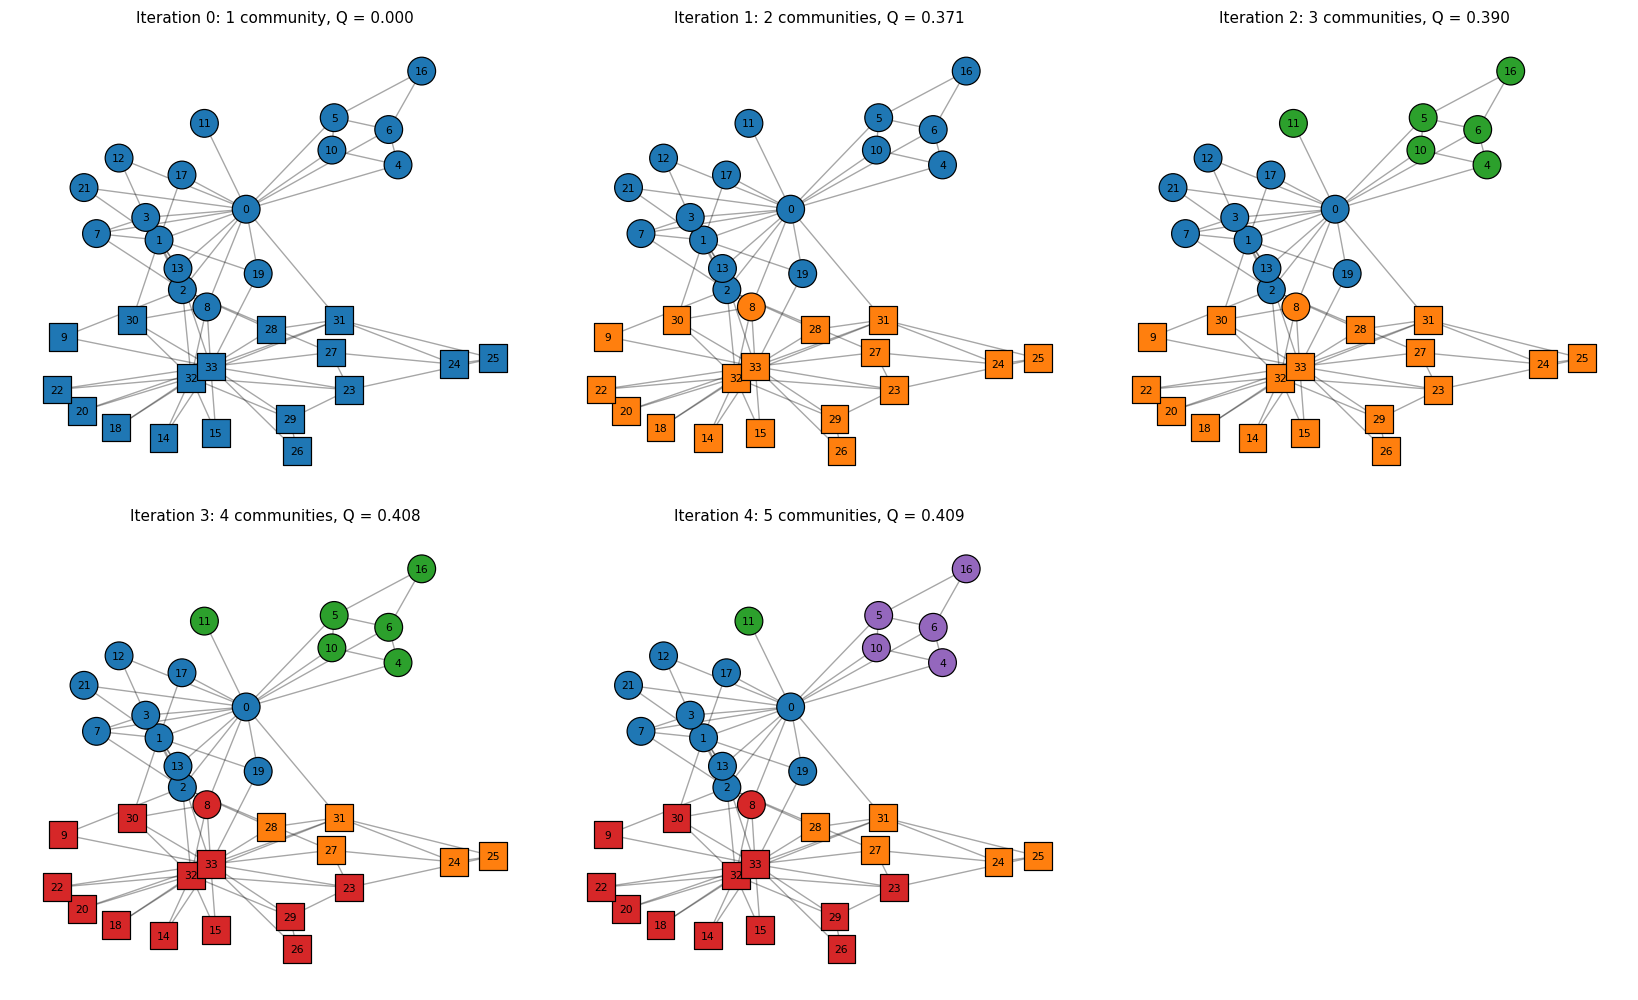

In [5]:
pos = nx.spring_layout(G, seed=SEED)
palette = plt.get_cmap("tab10")

def draw_partition(ax, G, pos, color_ids, title):
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=0.9)
    for shape, sign in (("o", 1), ("s", -1)):
        nl = [i for i in G.nodes() if truth[i] == sign]
        nx.draw_networkx_nodes(G, pos, nodelist=nl, node_shape=shape, ax=ax,
                               node_color=[palette(color_ids[i] % 10) for i in nl],
                               node_size=330, edgecolors="black", linewidths=0.8)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

ncols = 3
nrows = int(np.ceil(len(history) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.6 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, h in zip(axes, history):
    ttl = f"Iteration {h['iteration']}: {len(h['communities'])} communit{'y' if len(h['communities'])==1 else 'ies'}, Q = {h['Q']:.3f}"
    draw_partition(ax, G, pos, h["color"], ttl)
for ax in axes[len(history):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Node metrics after every split

Computing the four metrics on the *whole* graph `G` would give identical numbers after every split, because splitting only relabels nodes.
To make the metrics respond to the community structure, we compute them **inside each node's current community**
(on the induced subgraph `G.subgraph(C)`) with the NetworkX built-ins. Iteration 0 is the whole graph.
Note that NetworkX normalises by $|C|-1$, so values are relative to the size of the community the node lives in.

In [6]:
METRICS = ["degree", "betweenness", "closeness", "clustering"]

def node_metrics(G, communities):
    rec = {}
    for C in communities:
        H = G.subgraph(C)
        dc, bc = nx.degree_centrality(H), nx.betweenness_centrality(H)
        cc, cl = nx.closeness_centrality(H), nx.clustering(H)
        for v in C:
            rec[v] = dict(degree=dc[v], betweenness=bc[v], closeness=cc[v], clustering=cl[v])
    return pd.DataFrame.from_dict(rec, orient="index").sort_index()[METRICS]

metrics_by_iter = {h["iteration"]: node_metrics(G, h["communities"]) for h in history}   # dict keyed by iteration
iters = sorted(metrics_by_iter)

# one tidy cube: metric -> DataFrame (nodes x iterations)
evo = {mname: pd.DataFrame({f"it{t}": metrics_by_iter[t][mname] for t in iters}) for mname in METRICS}
print("Betweenness evolution for the first 8 nodes:")
print(evo["betweenness"].head(8).round(3))

Betweenness evolution for the first 8 nodes:
     it0    it1    it2    it3    it4
0  0.438  0.690  0.354  0.354  0.354
1  0.054  0.074  0.215  0.215  0.215
2  0.144  0.002  0.007  0.007  0.007
3  0.012  0.021  0.062  0.062  0.062
4  0.001  0.003  0.050  0.050  0.083
5  0.030  0.065  0.150  0.150  0.250
6  0.030  0.065  0.150  0.150  0.250
7  0.000  0.000  0.000  0.000  0.000


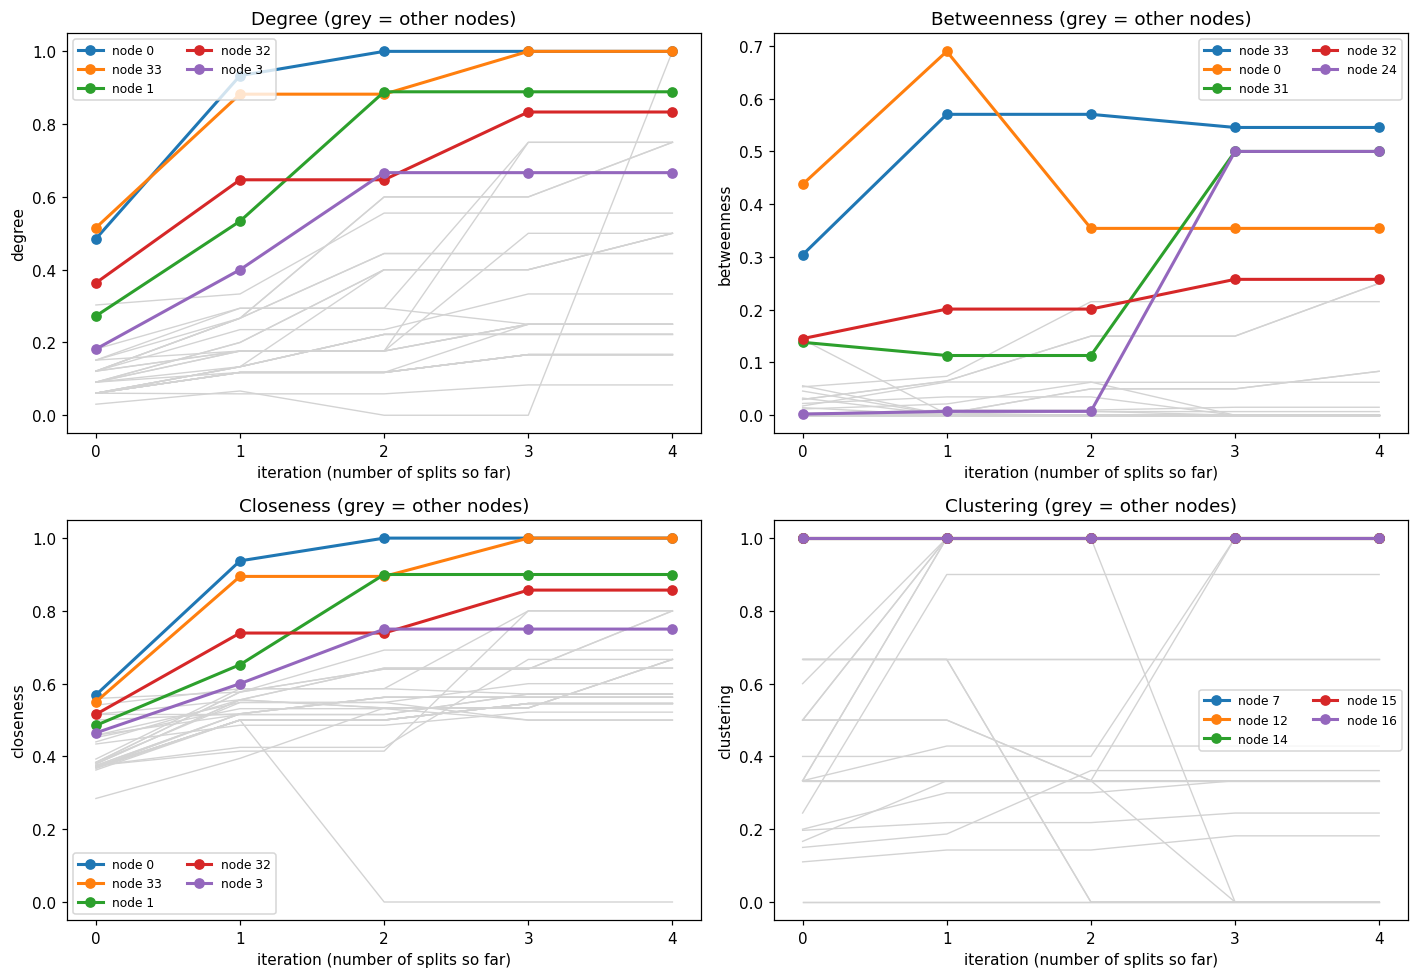

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, mname in zip(axes.ravel(), METRICS):
    df = evo[mname]
    top = df.mean(axis=1).nlargest(5).index
    for v in df.index:
        if v not in top:
            ax.plot(iters, df.loc[v].values, color="lightgray", lw=0.9, zorder=1)
    for j, v in enumerate(top):
        ax.plot(iters, df.loc[v].values, marker="o", lw=2, color=palette(j), label=f"node {v}", zorder=3)
    ax.set_title(f"{mname.capitalize()} (grey = other nodes)")
    ax.set_xlabel("iteration (number of splits so far)")
    ax.set_ylabel(mname)
    ax.set_xticks(iters)
    ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

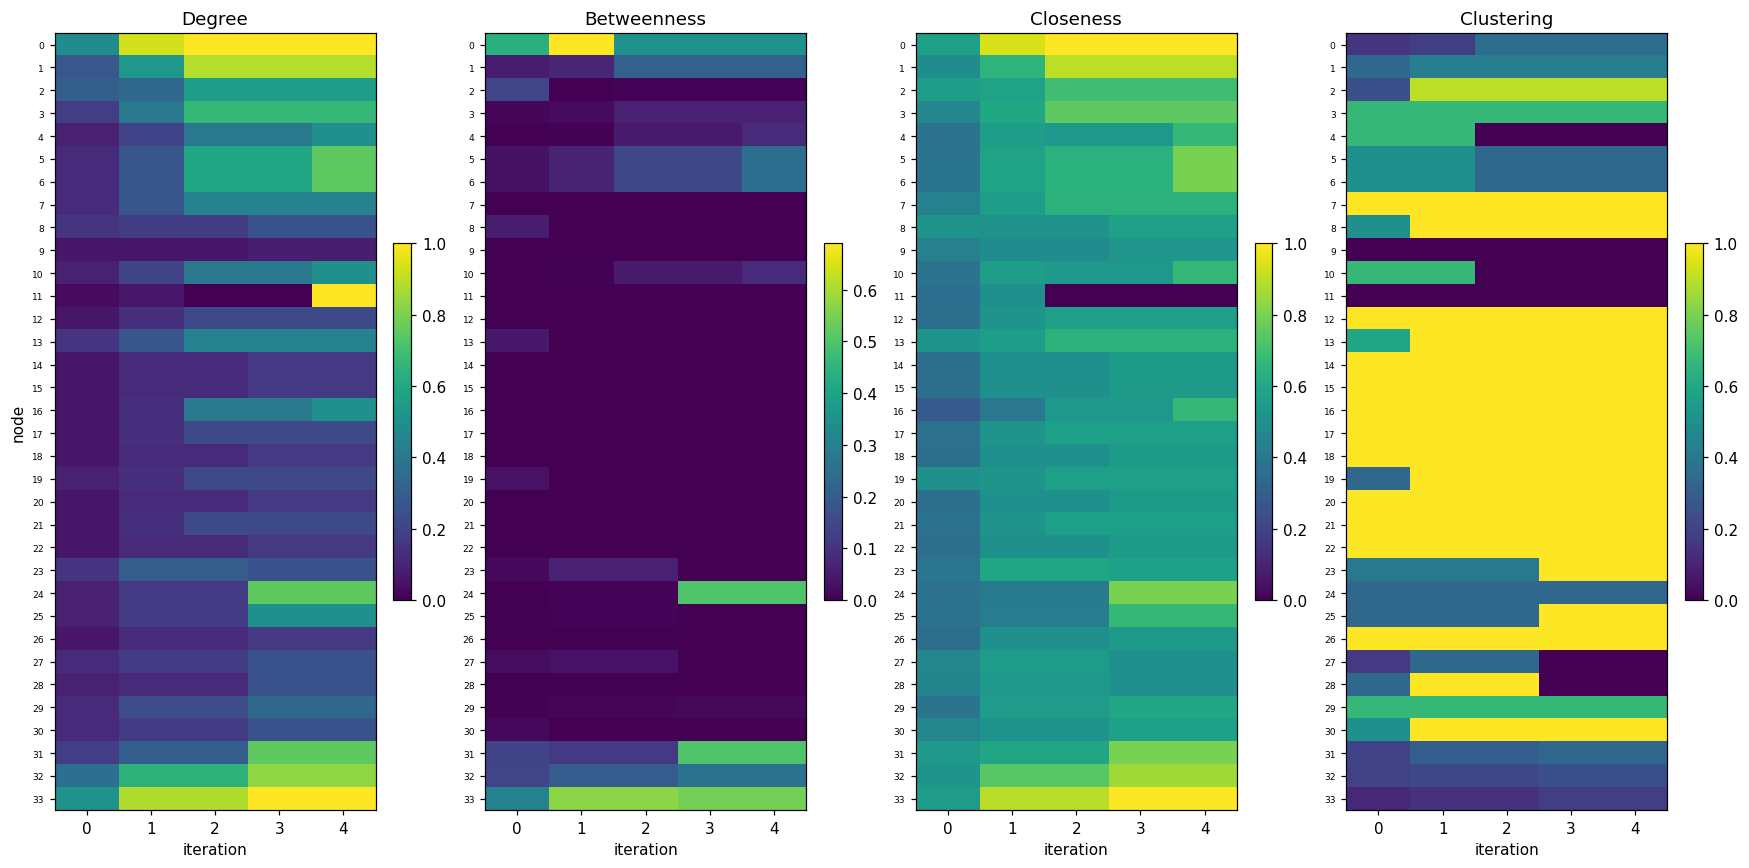

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 8))
for ax, mname in zip(axes, METRICS):
    df = evo[mname]
    im = ax.imshow(df.values, aspect="auto", cmap="viridis")
    ax.set_title(mname.capitalize())
    ax.set_xticks(range(len(iters))); ax.set_xticklabels(iters)
    ax.set_yticks(range(n)); ax.set_yticklabels(df.index, fontsize=6)
    ax.set_xlabel("iteration")
    plt.colorbar(im, ax=ax, fraction=0.05)
axes[0].set_ylabel("node")
plt.tight_layout()
plt.show()

### Which nodes stay central? Top-5 membership per iteration, and a global baseline

In [9]:
TOPK = 5
appear = pd.DataFrame(0, index=range(n), columns=METRICS)
for t in iters:
    for mname in METRICS:
        appear.loc[metrics_by_iter[t][mname].nlargest(TOPK).index, mname] += 1
appear["total"] = appear.sum(axis=1)
print(f"Number of iterations (out of {len(iters)}) in which a node is in the top-{TOPK}:")
print(appear.sort_values("total", ascending=False).head(8))

# Baseline on the full graph (what the metrics would be if we ignored the communities)
base = metrics_by_iter[0]
print("\nGlobal top-5 by each metric (iteration 0):")
for mname in METRICS:
    print(f"  {mname:12s}", list(base[mname].nlargest(TOPK).index))

Number of iterations (out of 5) in which a node is in the top-5:
    degree  betweenness  closeness  clustering  total
0        5            5          5           0     15
33       5            5          5           0     15
32       5            5          4           0     14
1        5            2          4           0     11
8        0            0          1           4      5
7        0            0          0           5      5
14       0            0          0           5      5
31       0            4          1           0      5

Global top-5 by each metric (iteration 0):
  degree       [33, 0, 32, 2, 1]
  betweenness  [0, 33, 32, 2, 31]
  closeness    [0, 2, 33, 31, 8]
  clustering   [7, 12, 14, 15, 16]


## 6. Does the first split recover the real club split?

In [10]:
first = history[1]
Cp, Cm = first["communities"][-2], first["communities"][-1]    # the two halves of the first split
pred = np.zeros(n, dtype=int)
pred[Cp], pred[Cm] = 1, -1
acc = max((pred == truth).mean(), (pred == -truth).mean())
if (pred == truth).mean() < (pred == -truth).mean():
    pred = -pred                                              # fix arbitrary eigenvector sign
wrong = [i for i in nodes if pred[i] != truth[i]]
print(f"Agreement of the first spectral split with the real split: {acc:.1%} ({int(round(acc*n))}/{n} members)")
print("Misclassified nodes:", wrong)
for i in wrong:
    print(f"  node {i}: real faction = {G.nodes[i]['club']}, degree = {int(k[i])}, "
          f"neighbours in Mr. Hi side = {sum(truth[j]==1 for j in G[i])}, in Officer side = {sum(truth[j]==-1 for j in G[i])}")

print("\nFinal communities vs. real factions:")
lab = np.zeros(n, dtype=int)
for ci, c in enumerate(sorted(final, key=lambda c: -len(c))):
    lab[c] = ci
print(pd.crosstab(pd.Series(lab, name="community"), pd.Series([G.nodes[i]["club"] for i in nodes], name="real faction")))

Agreement of the first spectral split with the real split: 97.1% (33/34 members)
Misclassified nodes: [8]
  node 8: real faction = Mr. Hi, degree = 5, neighbours in Mr. Hi side = 2, in Officer side = 3

Final communities vs. real factions:
real faction  Mr. Hi  Officer
community                    
0                  1       12
1                 10        0
2                  0        5
3                  5        0
4                  1        0


## 7. Extra samples: more graphs, more runs

To go beyond a single network we (a) run the algorithm on several other classic graphs, (b) compare against NetworkX's greedy and Louvain
modularity optimisers, and (c) test recovery on **planted-partition graphs (stochastic block models)** where the true communities are known.
We also compare the handout's block $B^{(C)}$ with Newman's full variant (generalized $B^{(C)}$ + gain check).

In [11]:
def adjusted_rand_index(a, b):
    a, b = np.asarray(a), np.asarray(b)
    ct = pd.crosstab(a, b).values
    s_ij = sum(comb(int(x), 2) for x in ct.ravel())
    s_a = sum(comb(int(x), 2) for x in ct.sum(axis=1))
    s_b = sum(comb(int(x), 2) for x in ct.sum(axis=0))
    expected = s_a * s_b / comb(len(a), 2)
    maxi = (s_a + s_b) / 2
    return 1.0 if maxi == expected else (s_ij - expected) / (maxi - expected)

def partition_to_labels(communities, n):
    lab = np.zeros(n, dtype=int)
    for ci, c in enumerate(communities):
        lab[list(c)] = ci
    return lab

def run_all_methods(Gx):
    nl = list(Gx.nodes())
    Ax = nx.to_numpy_array(Gx, nodelist=nl, weight=None)
    idx = {v: i for i, v in enumerate(nl)}
    out = {}
    for name, gen, rg in (("spectral (handout B)", False, False), ("spectral (Newman: gen. B + gain check)", True, True)):
        h, _ = recursive_bisection(Ax, generalized=gen, require_gain=rg)
        out[name] = (h[-1]["communities"], h[-1]["Q"])
    gr = [[idx[v] for v in c] for c in nx.community.greedy_modularity_communities(Gx)]
    lv = [[idx[v] for v in c] for c in nx.community.louvain_communities(Gx, seed=SEED)]
    out["greedy (NetworkX)"] = (gr, modularity_Q(Ax, gr))
    out["Louvain (NetworkX)"] = (lv, modularity_Q(Ax, lv))
    return out, nl

les = nx.Graph(nx.les_miserables_graph().edges())                 # drop weights -> simple graph
test_graphs = {
    "Karate Club": G,
    "Les Miserables": les,
    "Florentine families": nx.florentine_families_graph(),
    "Caveman (6 cliques of 8)": nx.connected_caveman_graph(6, 8),
    "Ring of 5 cliques (size 6)": nx.ring_of_cliques(5, 6),
}
rows = []
for gname, Gx in test_graphs.items():
    res, _ = run_all_methods(Gx)
    for meth, (comms, Q) in res.items():
        rows.append({"graph": gname, "n": Gx.number_of_nodes(), "m": Gx.number_of_edges(),
                     "method": meth, "#communities": len(comms), "Q": Q})
cmp_df = pd.DataFrame(rows)
print(cmp_df.pivot(index="graph", columns="method", values="Q").round(4).to_string())
print()
print(cmp_df.pivot(index="graph", columns="method", values="#communities").to_string())

method                      Louvain (NetworkX)  greedy (NetworkX)  spectral (Newman: gen. B + gain check)  spectral (handout B)
graph                                                                                                                          
Caveman (6 cliques of 8)                 0.798              0.798                                   0.724                 0.738
Florentine families                      0.398              0.399                                   0.364                 0.364
Karate Club                              0.385              0.381                                   0.393                 0.409
Les Miserables                           0.560              0.501                                   0.532                 0.530
Ring of 5 cliques (size 6)               0.738              0.738                                   0.687                 0.687

method                      Louvain (NetworkX)  greedy (NetworkX)  spectral (Newman: gen. B + gain chec

                     variant  p_out   ARI  ARI_sd  n_comm     Q
Newman (gen. B + gain check)   0.01 0.927   0.054     4.5 0.626
Newman (gen. B + gain check)   0.02 0.821   0.091     4.3 0.535
Newman (gen. B + gain check)   0.04 0.706   0.096     4.5 0.387
Newman (gen. B + gain check)   0.06 0.555   0.121     4.4 0.295
Newman (gen. B + gain check)   0.08 0.496   0.160     4.3 0.252
Newman (gen. B + gain check)   0.10 0.417   0.131     4.0 0.210
Newman (gen. B + gain check)   0.12 0.233   0.086     4.2 0.176
                   handout B   0.01 0.935   0.046     5.7 0.623
                   handout B   0.02 0.876   0.028     6.6 0.534
                   handout B   0.04 0.797   0.053     7.2 0.400
                   handout B   0.06 0.660   0.088     7.7 0.307
                   handout B   0.08 0.593   0.094     7.3 0.257
                   handout B   0.10 0.507   0.099     7.8 0.215
                   handout B   0.12 0.298   0.111     8.3 0.185


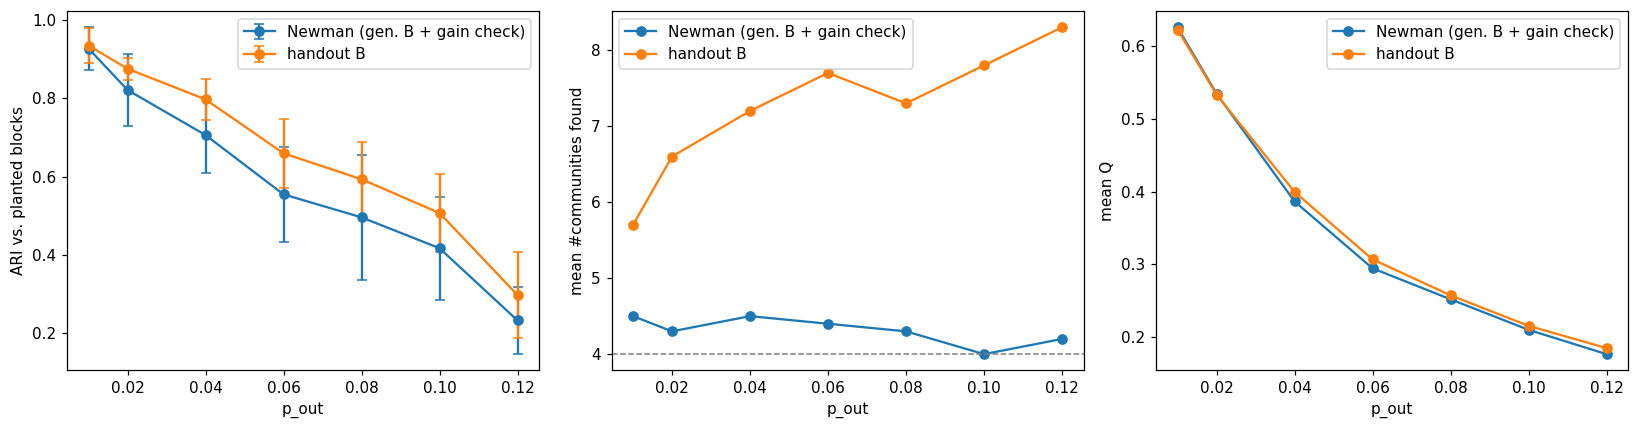

In [12]:
# Planted-partition experiment: 4 blocks of 25 nodes, p_in = 0.30, vary p_out; 10 random graphs each.
sizes, p_in = [25, 25, 25, 25], 0.30
p_out_grid = [0.01, 0.02, 0.04, 0.06, 0.08, 0.10, 0.12]
n_rep = 10
true_labels = np.repeat(np.arange(4), 25)

records = []
for p_out in p_out_grid:
    P = np.full((4, 4), p_out); np.fill_diagonal(P, p_in)
    for rep in range(n_rep):
        Gs = nx.stochastic_block_model(sizes, P, seed=1000 * rep + int(p_out * 1000))
        As = nx.to_numpy_array(Gs, nodelist=range(100), weight=None)
        for name, gen, rg in (("handout B", False, False), ("Newman (gen. B + gain check)", True, True)):
            h, _ = recursive_bisection(As, generalized=gen, require_gain=rg)
            comms = h[-1]["communities"]
            records.append(dict(p_out=p_out, rep=rep, variant=name, n_comm=len(comms), Q=h[-1]["Q"],
                                ARI=adjusted_rand_index(true_labels, partition_to_labels(comms, 100))))
sbm = pd.DataFrame(records)
agg = sbm.groupby(["variant", "p_out"]).agg(ARI=("ARI", "mean"), ARI_sd=("ARI", "std"),
                                           n_comm=("n_comm", "mean"), Q=("Q", "mean")).reset_index()
print(agg.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, grp in agg.groupby("variant"):
    axes[0].errorbar(grp.p_out, grp.ARI, yerr=grp.ARI_sd, marker="o", capsize=3, label=name)
    axes[1].plot(grp.p_out, grp.n_comm, marker="o", label=name)
    axes[2].plot(grp.p_out, grp.Q, marker="o", label=name)
axes[0].set_ylabel("ARI vs. planted blocks"); axes[1].set_ylabel("mean #communities found"); axes[2].set_ylabel("mean Q")
axes[1].axhline(4, color="gray", ls="--", lw=1)
for ax in axes:
    ax.set_xlabel("p_out"); ax.legend()
plt.tight_layout()
plt.show()

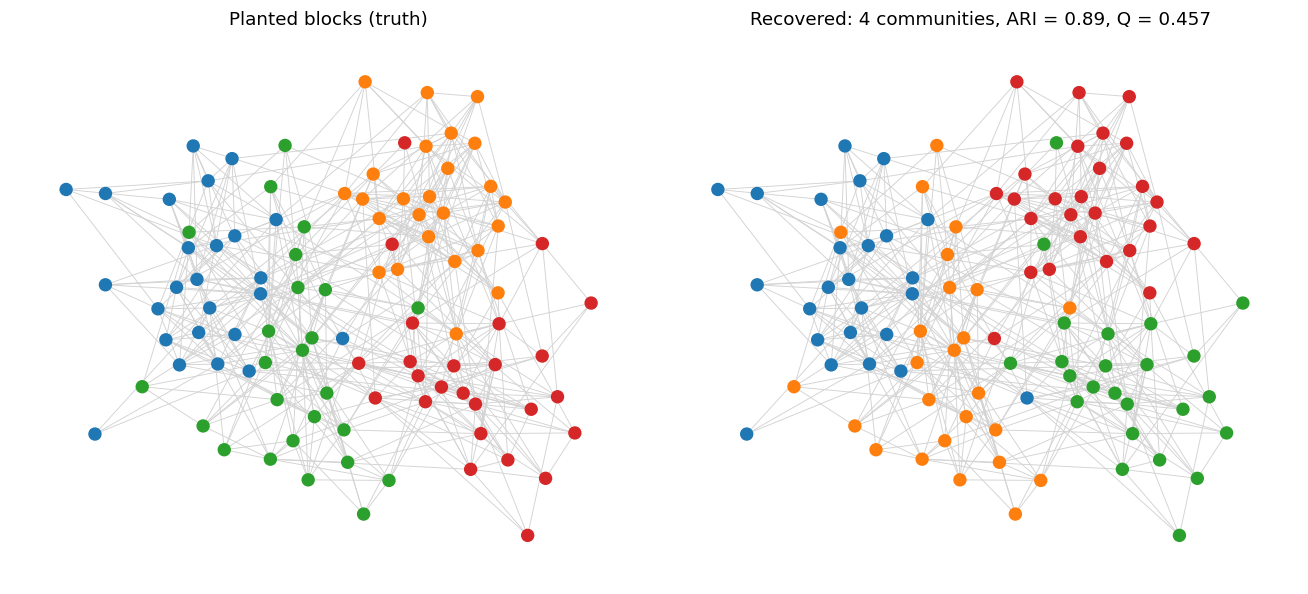

In [13]:
# One sample SBM graph drawn with the recovered communities (p_out = 0.04)
P = np.full((4, 4), 0.04); np.fill_diagonal(P, p_in)
Gs = nx.stochastic_block_model(sizes, P, seed=7)
As = nx.to_numpy_array(Gs, nodelist=range(100), weight=None)
h_s, _ = recursive_bisection(As, generalized=True, require_gain=True)
pos_s = nx.spring_layout(Gs, seed=SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
nx.draw_networkx(Gs, pos_s, ax=axes[0], node_color=[palette(b) for b in true_labels], node_size=60,
                 with_labels=False, edge_color="lightgray", width=0.6)
axes[0].set_title("Planted blocks (truth)")
col = partition_to_labels(h_s[-1]["communities"], 100)
nx.draw_networkx(Gs, pos_s, ax=axes[1], node_color=[palette(c % 10) for c in col], node_size=60,
                 with_labels=False, edge_color="lightgray", width=0.6)
axes[1].set_title(f"Recovered: {len(h_s[-1]['communities'])} communities, "
                  f"ARI = {adjusted_rand_index(true_labels, col):.2f}, Q = {h_s[-1]['Q']:.3f}")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

In [14]:
# Robustness check on Karate: handout B vs. Newman's full variant
hist_gen, _ = recursive_bisection(A, generalized=True, require_gain=True)
print("handout B     : Q per iteration =", [round(float(h["Q"]), 4) for h in history], "| final #comm =", len(history[-1]["communities"]))
print("Newman variant: Q per iteration =", [round(float(h["Q"]), 4) for h in hist_gen], "| final #comm =", len(hist_gen[-1]["communities"]))
same = sorted(map(sorted, history[-1]["communities"])) == sorted(map(sorted, hist_gen[-1]["communities"]))
print("Identical final partitions:", same)

handout B     : Q per iteration = [0.0, 0.3715, 0.3898, 0.4081, 0.4094] | final #comm = 5
Newman variant: Q per iteration = [0.0, 0.3715, 0.3727, 0.3934] | final #comm = 4
Identical final partitions: False


## 8. Discussion
*(Draft written from the outputs above. Re-read it, check every number against your own run, and rewrite it in your own words, since the end-semester question will be on the concepts.)*

**What the algorithm did.** The first split ($\lambda_1 = 4.977$, sizes 16 + 18, $Q = 0.371$) reproduces Zachary's real split for 33 of 34 members.
The one error is node 8: it has degree 5, with 3 neighbours on the Officer side and 2 on Mr. Hi's side, so from the graph alone it looks like an Officer member
although it actually followed Mr. Hi. Three more splits follow, with the true modularity gains getting smaller each time
($+0.018$, $+0.018$, $+0.001$) and final $Q = 0.409$ with 5 communities. The last split only cuts off node 11, a degree-1 node attached to node 0, and gains almost nothing.
That is a sign the recursion is starting to fit small details rather than real structure.

**Which nodes stay central.** Nodes **0** and **33** (the two faction leaders, Mr. Hi and the Officer) are in the top five for degree, betweenness and closeness in
**every** iteration (5 of 5), followed by node **32** and node **1**. They are also the global top hubs at iteration 0. Their dominance is *structural*: the factions are
built around them, so splitting the graph along faction lines does not remove them from the centre of their own community.
Nodes 7, 12, 14, 15 and 16 keep clustering coefficient 1 throughout (many ties at the top), because their few neighbours are mutually connected and those neighbours stay in the same community.

**How community structure changes the metrics.**
* *Degree and closeness rise* after each split, since they are normalised by $|C|-1$ and communities are small and dense: node 0 reaches degree centrality 1.0 once it sits in a 10-node community that it is connected to entirely.
* *Betweenness* reacts most strongly. Node 0 jumps from 0.438 to 0.690 after the first split, then falls to 0.354 once the periphery group {4, 5, 6, 10, 16, 11} is split away
  and its paths no longer pass through node 0. Nodes 24 and 31 jump from about 0 to 0.5 once they live in the 5-node community {24, 25, 27, 28, 31}, where they become the brokers.
* *Closeness collapses to 0* for node 11 at iteration 2: its only neighbour (node 0) is in another community, so inside its own community it is isolated.
* *Clustering* is local, so it only changes when a node's neighbours are separated from it (the grey lines that drop to 0).

**Caveats.** (i) The handout's $B^{(C)}$ is the plain block of $B$; its quadratic form is not the exact modularity change (Newman subtracts the row sums on the diagonal and checks that $Q$ really increases).
On Karate this gives 4 communities instead of 5 with a slightly lower $Q$ (0.393 vs. 0.409). (ii) In the planted-partition experiment (4 blocks of 25 nodes, 10 graphs per setting),
recovery (ARI) falls as $p_{out}$ grows for both variants. The handout variant over-splits (about 6 to 8 communities instead of 4) but has the higher ARI for $p_{out}\le 0.12$ in the averages shown,
while Newman's variant finds about 4 to 4.5 communities. (iii) Louvain and greedy are heuristics too; on Karate the spectral method's $Q$ is higher than their $Q$ in our runs, but that does not make it the global optimum.